# Week 1 – Data Acquisition, Cleaning and EDA
**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)
**Author:** Anish Goyal

Goal for this week: take a public dataset, clean it properly with pandas, and explore it to see which customer
characteristics are linked to churn. Modelling comes later; this notebook only prepares and understands the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RAW = Path("../data/raw/Telco-Customer-Churn.csv")
OUT_DATA = Path("../data/processed")
OUT_FIG = Path("../reports/figures")
OUT_DATA.mkdir(parents=True, exist_ok=True)
OUT_FIG.mkdir(parents=True, exist_ok=True)

## 1. Data acquisition
The CSV is published by IBM in their public GitHub repo (`IBM/telco-customer-churn-on-icp4d`).
I downloaded it once into `data/raw/` so the notebook does not depend on the internet every time it runs.
The download command is kept below for reproducibility.

In [2]:
# Run once if the raw file is missing:
# !curl -L -o ../data/raw/Telco-Customer-Churn.csv https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

df_raw = pd.read_csv(RAW)
print(df_raw.shape)
df_raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. First look at the raw data

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# value check for every text column - helps spot odd categories or numbers stored as text
for col in df_raw.columns:
    if df_raw[col].dtype.kind not in "if":
        print(f"{col:<18} {df_raw[col].nunique():>5} unique  ->  {list(df_raw[col].unique()[:4])}")

customerID          7043 unique  ->  ['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW']
gender                 2 unique  ->  ['Female', 'Male']
Partner                2 unique  ->  ['Yes', 'No']
Dependents             2 unique  ->  ['No', 'Yes']
PhoneService           2 unique  ->  ['No', 'Yes']
MultipleLines          3 unique  ->  ['No phone service', 'No', 'Yes']
InternetService        3 unique  ->  ['DSL', 'Fiber optic', 'No']
OnlineSecurity         3 unique  ->  ['No', 'Yes', 'No internet service']
OnlineBackup           3 unique  ->  ['Yes', 'No', 'No internet service']
DeviceProtection       3 unique  ->  ['No', 'Yes', 'No internet service']
TechSupport            3 unique  ->  ['No', 'Yes', 'No internet service']
StreamingTV            3 unique  ->  ['No', 'Yes', 'No internet service']
StreamingMovies        3 unique  ->  ['No', 'Yes', 'No internet service']
Contract               3 unique  ->  ['Month-to-month', 'One year', 'Two year']
PaperlessBilling       2 unique  -> 

Things I noticed:
- `TotalCharges` is a money column but pandas read it as text, so some rows must contain non-numeric values.
- `SeniorCitizen` is coded 0/1 while every other yes/no column uses "Yes"/"No".
- Six service columns use a third level, "No internet service", and `MultipleLines` uses "No phone service".

## 3. Data cleaning

### 3.1 Fixing the data type of TotalCharges

In [5]:
df = df_raw.copy()

blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges:", blank_mask.sum())
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 blank rows have `tenure = 0`. These are customers who just joined and have not been billed yet,
so their total charge is genuinely 0. Filling with 0 is more accurate than dropping them or filling with the
mean/median (the median would give a brand-new customer a bill of ~1,400).

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip().replace("", "0"))
print(df["TotalCharges"].dtype, "| missing after fix:", df["TotalCharges"].isna().sum())

float64 | missing after fix: 0


### 3.2 Missing values in the whole dataset

Total missing cells: 0


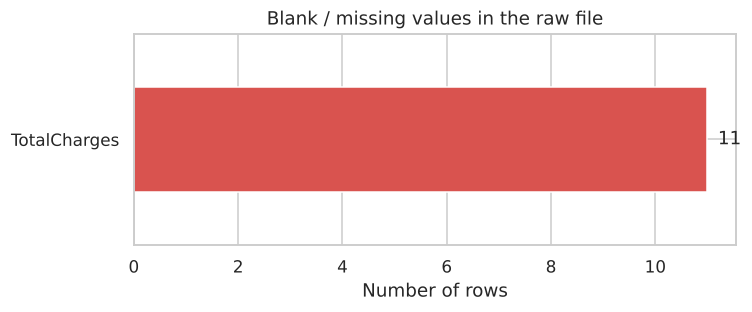

In [7]:
missing = df.isna().sum()
print("Total missing cells:", missing.sum())

# plot the raw blank cells (before the fix) so the issue is visible in the report
raw_missing = (df_raw.astype(str).apply(lambda s: s.str.strip() == "")).sum()
raw_missing = raw_missing[raw_missing > 0]

fig, ax = plt.subplots(figsize=(7, 3))
raw_missing.plot(kind="barh", color="#d9534f", ax=ax)
ax.set_title("Blank / missing values in the raw file")
ax.set_xlabel("Number of rows")
for i, v in enumerate(raw_missing.values):
    ax.text(v + 0.2, i, str(v), va="center")
plt.tight_layout()
plt.savefig(OUT_FIG / "01_missing_values.png", bbox_inches="tight")
plt.show()

### 3.3 Duplicates

In [8]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Duplicates if we ignore customerID:", df.drop(columns="customerID").duplicated().sum())

Exact duplicate rows: 0
Duplicate customer IDs: 0
Duplicates if we ignore customerID: 22


There are no exact duplicates and every `customerID` is unique. 22 rows match another row on all other columns,
but on inspection they are short-tenure customers on the most basic plans, where identical profiles are expected.
Since the IDs are different, these are separate people, so I kept them. Dropping them would remove real customers.

In [9]:
dup_profiles = df[df.drop(columns="customerID").duplicated(keep=False)]
dup_profiles[["tenure", "InternetService", "Contract", "MonthlyCharges"]].describe(include="all").loc[["count", "mean", "top"]]

,tenure,InternetService,Contract,MonthlyCharges
count,42.0,42,42,42.000000
mean,1.0,NaN,NaN,36.729762
top,NaN,No,Month-to-month,NaN


### 3.4 Making categories consistent

In [10]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

internet_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
for col in internet_cols:
    df[col] = df[col].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

cat_cols = [c for c in df.columns if df[c].dtype.kind not in "if" and c != "customerID"]
df[cat_cols] = df[cat_cols].astype("category")

df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # numeric copy for rates and correlations

"No internet service" already appears in `InternetService = No`, so repeating it in six other columns only adds
redundancy. Merging it into "No" keeps the information (the customer does not have that add-on) and makes each column binary.

### 3.5 Outlier check

In [11]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:<15} IQR outliers: {n_out}")

tenure          IQR outliers: 0
MonthlyCharges  IQR outliers: 0
TotalCharges    IQR outliers: 0


No values fall outside the 1.5×IQR fences, so no outlier treatment is needed.

### 3.6 Feature for later analysis: tenure groups

In [12]:
bins = [-1, 12, 24, 48, 72]
labels = ["0-12 m", "13-24 m", "25-48 m", "49-72 m"]
df["TenureGroup"] = pd.cut(df["tenure"], bins=bins, labels=labels)
df["TenureGroup"].value_counts().sort_index()

TenureGroup
0-12 m     2186
13-24 m    1024
25-48 m    1594
49-72 m    2239
Name: count, dtype: int64

In [13]:
df.to_csv(OUT_DATA / "telco_churn_clean.csv", index=False)
print("Saved cleaned data:", df.shape)
df.info()

Saved cleaned data: (7043, 23)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   str     
 1   gender            7043 non-null   category
 2   SeniorCitizen     7043 non-null   category
 3   Partner           7043 non-null   category
 4   Dependents        7043 non-null   category
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   category
 7   MultipleLines     7043 non-null   category
 8   InternetService   7043 non-null   category
 9   OnlineSecurity    7043 non-null   category
 10  OnlineBackup      7043 non-null   category
 11  DeviceProtection  7043 non-null   category
 12  TechSupport       7043 non-null   category
 13  StreamingTV       7043 non-null   category
 14  StreamingMovies   7043 non-null   category
 15  Contract          7043 non-null   category
 16  Pape

## 4. Exploratory data analysis

### 4.1 Summary statistics

In [14]:
df[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [15]:
df.groupby("Churn", observed=True)[num_cols].median().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


### 4.2 Target balance

In [16]:
churn_share = df["Churn"].value_counts(normalize=True).mul(100).round(1)
print(churn_share)

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


### 4.3 Distribution of the numeric columns by churn

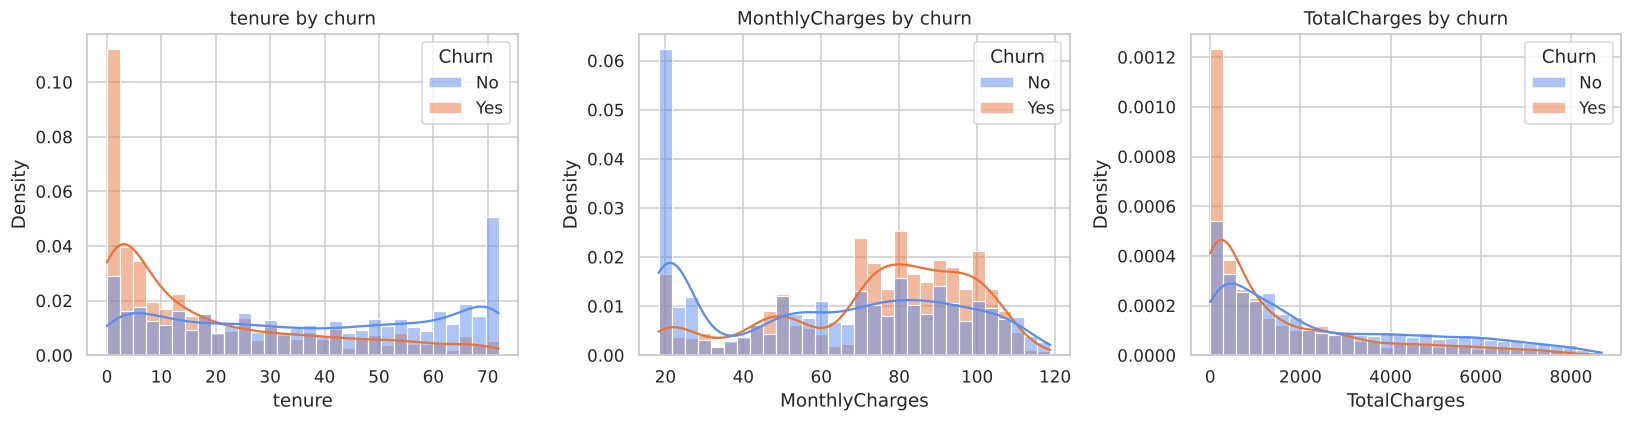

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, kde=True,
                 stat="density", common_norm=False, ax=ax, palette=["#5b8def", "#e8743b"])
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig(OUT_FIG / "02_numeric_distributions.png", bbox_inches="tight")
plt.show()

### 4.4 Box plots

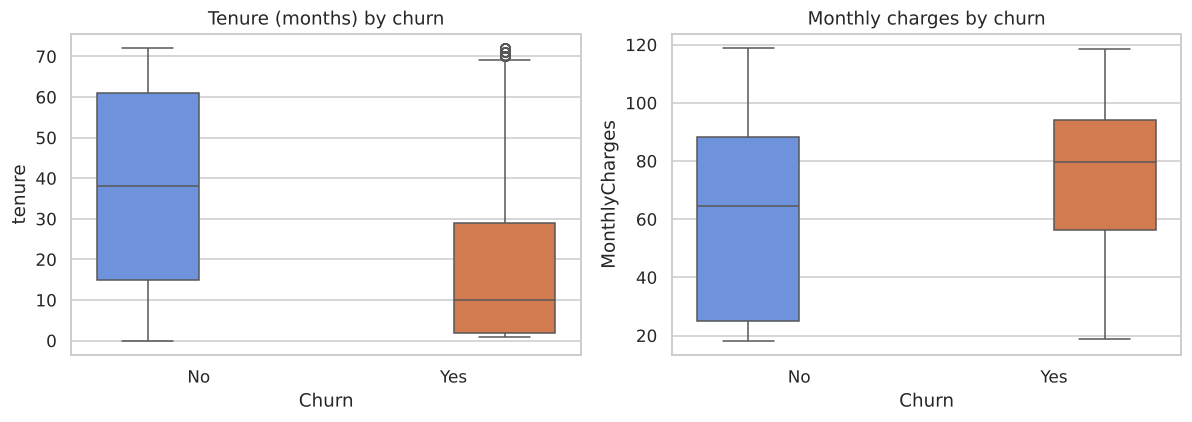

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0], palette=["#5b8def", "#e8743b"], hue="Churn", legend=False)
axes[0].set_title("Tenure (months) by churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette=["#5b8def", "#e8743b"], hue="Churn", legend=False)
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.savefig(OUT_FIG / "03_boxplots.png", bbox_inches="tight")
plt.show()

### 4.5 Churn rate across categories

In [19]:
def churn_rate(col):
    return (df.groupby(col, observed=True)["ChurnFlag"].mean() * 100).round(1).sort_values(ascending=False)

for col in ["Contract", "InternetService", "PaymentMethod", "TenureGroup",
            "TechSupport", "OnlineSecurity", "SeniorCitizen", "PaperlessBilling", "gender"]:
    print(churn_rate(col).to_string(), "\n")

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4 

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2 

TenureGroup
0-12 m     47.4
13-24 m    28.7
25-48 m    20.4
49-72 m     9.5 

TechSupport
No     31.2
Yes    15.2 

OnlineSecurity
No     31.3
Yes    14.6 

SeniorCitizen
Yes    41.7
No     23.6 

PaperlessBilling
Yes    33.6
No     16.3 

gender
Female    26.9
Male      26.2 



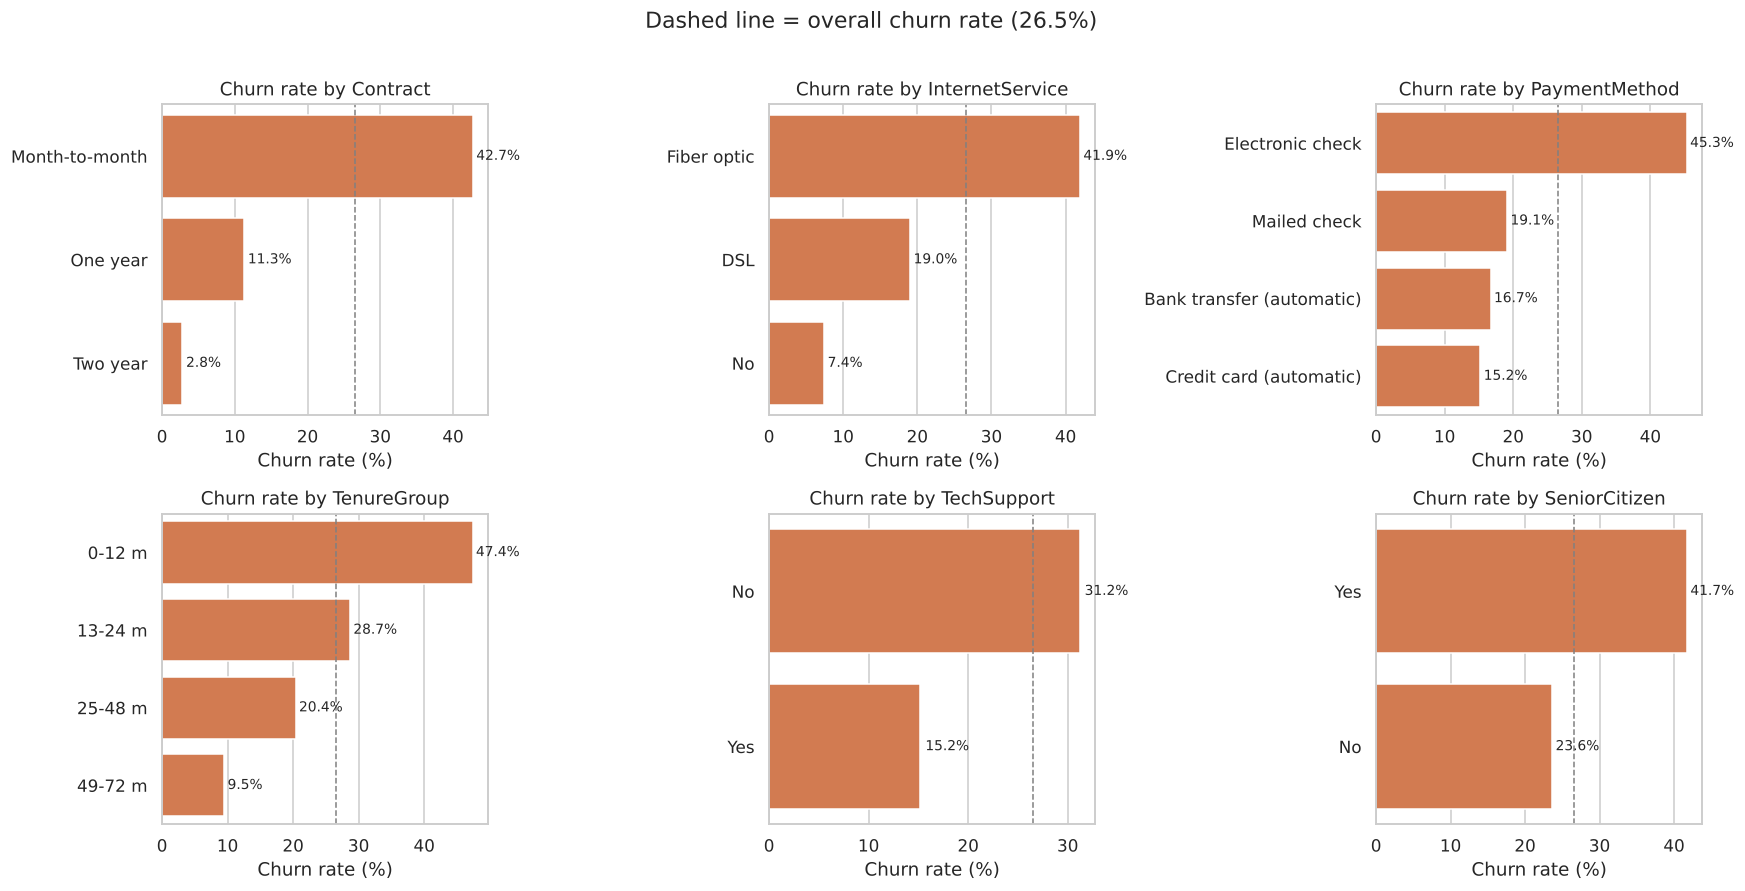

In [20]:
plot_cols = ["Contract", "InternetService", "PaymentMethod", "TenureGroup", "TechSupport", "SeniorCitizen"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
overall = df["ChurnFlag"].mean() * 100
for ax, col in zip(axes.flat, plot_cols):
    rate = churn_rate(col)
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax, color="#e8743b")
    ax.axvline(overall, ls="--", color="grey", lw=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    for i, v in enumerate(rate.values):
        ax.text(v + 0.5, i, f"{v}%", va="center", fontsize=9)
plt.suptitle(f"Dashed line = overall churn rate ({overall:.1f}%)", y=1.01)
plt.tight_layout()
plt.savefig(OUT_FIG / "04_churn_rate_by_category.png", bbox_inches="tight")
plt.show()

### 4.6 Correlations

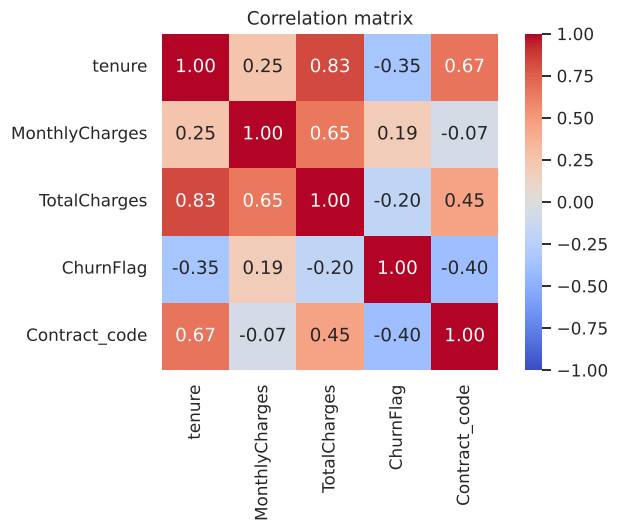

,tenure,MonthlyCharges,TotalCharges,ChurnFlag,Contract_code
tenure,1.00,0.25,0.83,-0.35,0.67
MonthlyCharges,0.25,1.00,0.65,0.19,-0.07
TotalCharges,0.83,0.65,1.00,-0.20,0.45
ChurnFlag,-0.35,0.19,-0.20,1.00,-0.40
Contract_code,0.67,-0.07,0.45,-0.40,1.00


In [21]:
corr_df = df[num_cols + ["ChurnFlag"]].copy()
corr_df["Contract_code"] = df["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2}).astype(int)
corr = corr_df.corr().round(2)

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True, fmt=".2f")
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(OUT_FIG / "05_correlation_heatmap.png", bbox_inches="tight")
plt.show()
corr

### 4.7 Tenure vs monthly charges

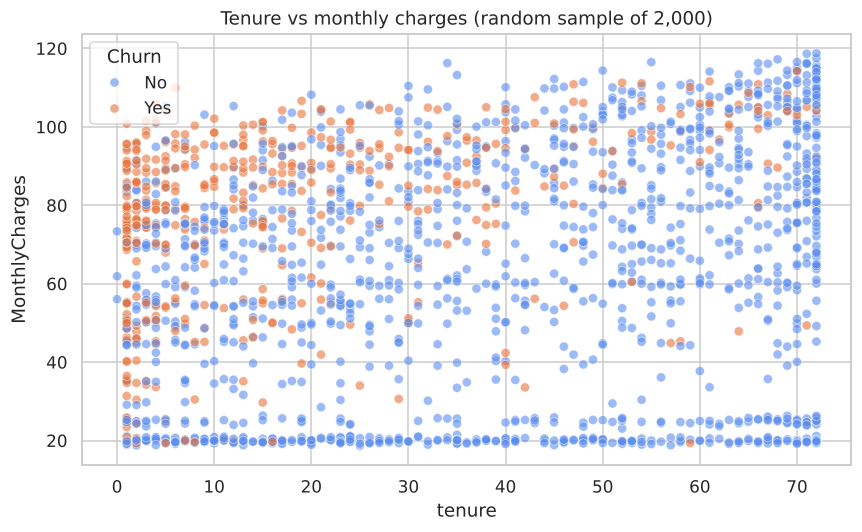

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(2000, random_state=42), x="tenure", y="MonthlyCharges",
                hue="Churn", alpha=0.6, palette=["#5b8def", "#e8743b"])
plt.title("Tenure vs monthly charges (random sample of 2,000)")
plt.tight_layout()
plt.savefig(OUT_FIG / "06_tenure_vs_charges.png", bbox_inches="tight")
plt.show()

## 5. Key insights
1. **Overall churn is about 26.5%**, so the target is imbalanced (roughly 3:1). This needs stratified splits and
   metrics like recall/F1 when modelling.
2. **Contract type matters most.** Month-to-month customers churn at about 43%, compared with about 11% on
   one-year and under 3% on two-year contracts.
3. **New customers are the riskiest.** Churn is close to 47% in the first 12 months and drops to under 10% after
   4 years. Median tenure of churners is 10 months vs 38 for those who stay.
4. **Fiber optic users churn more (~42%)** even though it is the premium service. Together with higher monthly
   charges among churners, this suggests price or service quality issues on fiber.
5. **Electronic check payers churn at ~45%**, far above automatic payment methods (~15–17%).
6. **Missing add-ons such as Tech Support and Online Security** go with much higher churn.
7. **Gender has almost no effect**, so it is unlikely to be a useful predictor.

## 6. Areas for further analysis
- Build a classification model (logistic regression, random forest) using the cleaned file.
- Test whether the fiber-optic effect stays after controlling for contract type and charges.
- Look at interaction effects, e.g. month-to-month + electronic check + fiber.
- Estimate revenue at risk by combining churn probability with `MonthlyCharges`.